# 01 · First look: the post-COVID tech boom and bust

**Question behind the project:** how did the boom and bust change *where* tech work happens, *what skills* it asks for, and *who* loses their job?

This notebook is the first look at the data we already have. It does **not** answer the question; it checks whether the story is visible and where it is not.
Everything is read from one file, `data/processed/it_employment_master.csv` (see `DATA_DICTIONARY.md`). Run `python build_master.py` first.

**Reading rules (from the data dictionary):** compare *trends*, not levels, across sources; sum only `granularity == 'detailed'` rows within one dataset; the 2026 figures are partial years; Hacker News and layoffs are samples, not the whole market.

In [2]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "build_master.py").exists())
MASTER = ROOT / "data" / "processed" / "it_employment_master.csv"
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 12, "axes.titleweight": "bold"})
EVENTS = {"COVID-19\n(Mar 2020)": "2020-03-11", "Fed starts\nhiking (Mar 2022)": "2022-03-16", "ChatGPT\n(Nov 2022)": "2022-11-30"}

m = pd.read_csv(MASTER, keep_default_na=False, dtype={"industry_code": str})
m["value"] = pd.to_numeric(m["value"], errors="coerce")
m["date"] = pd.to_datetime(m["date"])
m["year"] = m["date"].dt.year

def sel(df, **kw):
    mask = pd.Series(True, index=df.index)
    for k, v in kw.items():
        mask &= df[k].isin(v) if isinstance(v, (list, tuple, set)) else (df[k] == v)
    return df[mask]

def no_partial(df): return df[df["quality_flag"] != "partial_month"]

def events(ax, labels=True):
    lo, hi = ax.get_xlim(); y0, y1 = ax.get_ylim()
    for i, (name, d) in enumerate(EVENTS.items()):
        x = pd.Timestamp(d)
        if lo <= ax.xaxis.convert_xunits(x) <= hi:
            ax.axvline(x, color="grey", ls="--", lw=0.8)
            if labels:  # stagger heights so neighbouring labels never overlap
                ax.text(x, y1 - (y1 - y0) * 0.09 * (i % 3), " " + name.replace("\n", " "), va="top", fontsize=7, color="grey")

def save(fig, name): fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

print(f"{len(m):,} rows from {m.dataset.nunique()} datasets")
m.groupby("dataset").agg(rows=("value", "size"), first=("date", "min"), last=("date", "max"), series=("series_id", "nunique"))

33,788 rows from 12 datasets


C:\Users\USER\AppData\Local\Temp\ipykernel_18476\1462090865.py:13: DtypeWarning: Columns (10: value) have mixed types. Specify dtype option on import or set low_memory=False.
  m = pd.read_csv(MASTER, keep_default_na=False, dtype={"industry_code": str})


,rows,first,last,series
dataset,,,,
bls_ces,704,2015-01-01,2026-09-01,5
bls_qcew,1080,2015-01-01,2026-01-01,27
eurostat_isoc_sks_itspa,2904,2004-01-01,2025-01-01,148
eurostat_isoc_sks_itspe,3070,2004-01-01,2025-01-01,170
eurostat_isoc_sks_itsps,2886,2004-01-01,2025-01-01,148
eurostat_isoc_sks_itspt,1452,2004-01-01,2025-01-01,74
eurostat_lfsa_egan22d,4243,2008-01-01,2025-01-01,263
hn_whoishiring,5180,2015-01-01,2026-10-01,37
indeed_aggregate,2592,2020-02-01,2026-10-01,32


## 1 · US employment: a boom, then a plateau (not a collapse)
CES monthly employment, averaged by calendar year and indexed to **2019 = 100**. *2026 covers January to September only.*

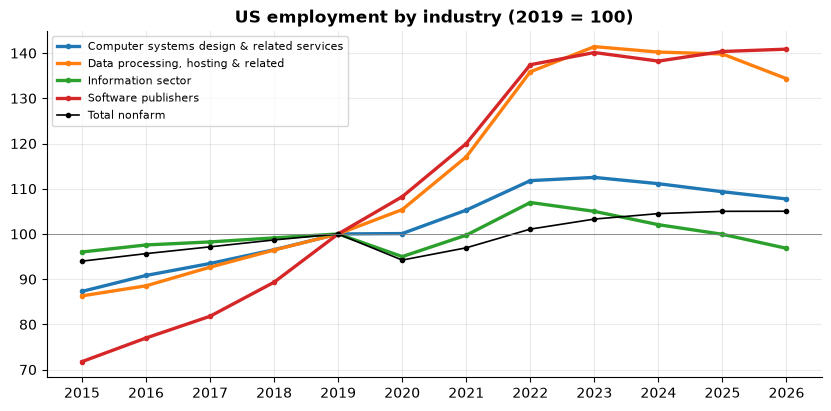

,Computer systems design & related services,"Data processing, hosting & related",Information sector,Software publishers,Total nonfarm
year,,,,,
2021,105.3,117.0,99.7,120.0,96.9
2022,111.8,135.9,107.0,137.4,101.1
2023,112.5,141.4,105.0,140.1,103.3
2024,111.1,140.2,102.0,138.2,104.5
2025,109.3,139.8,99.9,140.4,105.0
2026,107.7,134.3,96.8,140.9,105.0


In [3]:
ces = sel(m, dataset="bls_ces")
ann = ces.groupby(["segment", "year"]).value.mean().unstack(0)
idx = (ann / ann.loc[2019] * 100).loc[2015:]
idx.columns = [c.split(" (")[0] for c in idx.columns]
fig, ax = plt.subplots()
for c in idx.columns:
    ax.plot(idx.index, idx[c], marker="o", ms=3, lw=2.4 if c != "Total nonfarm" else 1.2,
            color="black" if c == "Total nonfarm" else None, label=c)
ax.axhline(100, color="grey", lw=0.6); ax.set_title("US employment by industry (2019 = 100)")
ax.legend(fontsize=8); ax.set_xticks(idx.index)
save(fig, "01_us_employment_index"); plt.show()
idx.round(1).tail(6)

## 2 · US IT services (QCEW): the same story in a second source
Sum of the detailed IT-services industries (custom programming, systems design, facilities management, other), quarterly, thousand employees.

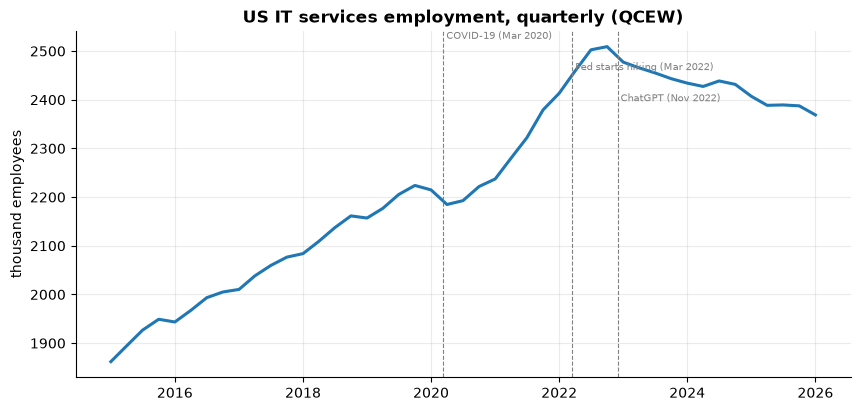

Peak 2,509k in 2022-Q4; latest 2,369k (-5.6% vs peak)


In [4]:
q = sel(m, dataset="bls_qcew", metric="employment_level", granularity="detailed", segment_group="IT services")
qs = q.groupby("date").value.sum()
fig, ax = plt.subplots()
ax.plot(qs.index, qs.values, lw=2.2); ax.set_ylabel("thousand employees")
ax.set_title("US IT services employment, quarterly (QCEW)"); events(ax)
save(fig, "02_us_it_services_qcew"); plt.show()
peak = qs.idxmax(); print(f"Peak {qs.max():,.0f}k in {peak:%Y-Q}{(peak.month-1)//3+1}; latest {qs.iloc[-1]:,.0f}k ({qs.iloc[-1]/qs.max()-1:+.1%} vs peak)")

## 3 · Hiring demand: the clearest bust
Indeed postings index (**1 Feb 2020 = 100**), monthly mean. Left: software development. Right: all job postings (seasonally adjusted).

**Look for:** the peak in early 2022 in every country, and the divergence since mid-2025: US software postings have been recovering while Germany, France and the UK keep falling.

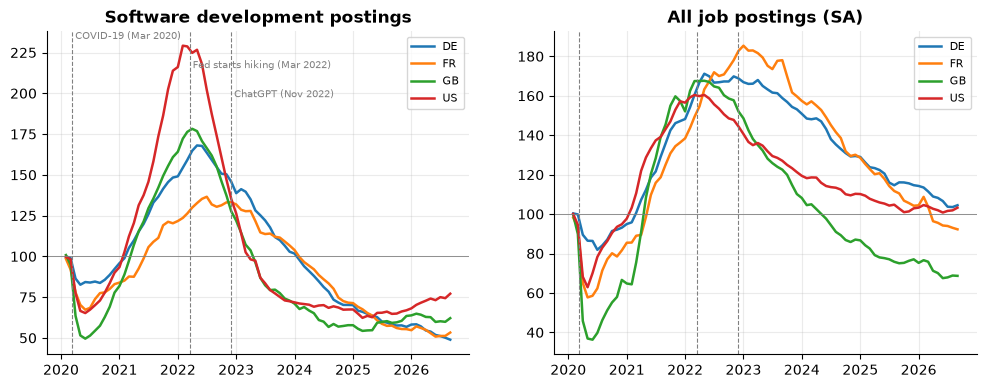

DE: peak 168 (2022-05), latest 49 (-71% vs peak)
FR: peak 137 (2022-07), latest 53 (-61% vs peak)
GB: peak 178 (2022-04), latest 62 (-65% vs peak)
US: peak 229 (2022-02), latest 77 (-66% vs peak)


In [5]:
ind = no_partial(m)
sd = sel(ind, dataset="indeed_it_sector", segment="Software Development", breakdown="variable=total postings")
al = sel(ind, dataset="indeed_aggregate", breakdown="variable=total postings;seasonal=SA")
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), sharey=False)
for ax, d, t in [(axs[0], sd, "Software development postings"), (axs[1], al, "All job postings (SA)")]:
    for c, g in d[d.country.isin(["US", "GB", "DE", "FR"])].groupby("country"):
        ax.plot(g["date"], g["value"], label=c, lw=1.8)
    ax.axhline(100, color="grey", lw=0.6); ax.set_title(t); ax.legend(fontsize=8); events(ax, labels=(ax is axs[0]))
save(fig, "03_indeed_postings"); plt.show()
for c, g in sd.groupby("country"):
    g = g.set_index("date")["value"]; print(f"{c}: peak {g.max():.0f} ({g.idxmax():%Y-%m}), latest {g.iloc[-1]:.0f} ({g.iloc[-1]/g.max()-1:+.0%} vs peak)")

## 4 · Layoffs: who is hit, and when
Layoff events per month in the tracker (3-month rolling sum), US vs Europe. The tracker is crowdsourced and only lists companies **with** layoffs, so read this as the shape of the wave, not its size.

**Look for two waves:** a sharp COVID shock in spring 2020 (many events, short-lived) and the 2022-2023 correction (longer, and with far larger headcounts). Event counts alone make the two look similar; the headcount table below separates them.

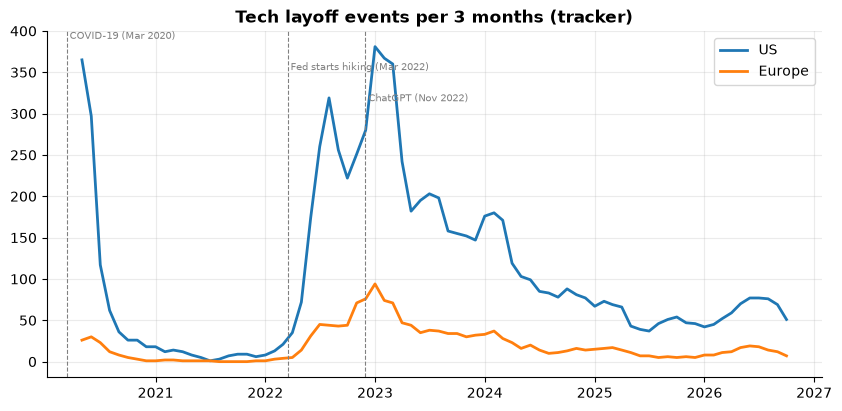

metric       layoff_events  layoff_headcount
year region                                 
2020 Europe           41.0            7571.0
     US              455.0           50380.0
2021 Europe            4.0             407.0
     US               32.0            9470.0
2022 Europe          154.0           17096.0
     US              731.0          108546.0
2023 Europe          172.0           48387.0
     US              860.0          178725.0
2024 Europe           73.0           22381.0
     US              425.0          106727.0
2025 Europe           35.0            6952.0
     US              205.0          102756.0
2026 Europe           42.0            8305.0
     US              202.0          106367.0

In [6]:
lo = sel(m, dataset="layoffs_tracker", metric="layoff_events", segment_group="All industries")
ev = lo.groupby(["date", "region"]).value.sum().unstack().fillna(0)
ev = ev.asfreq("MS", fill_value=0)
fig, ax = plt.subplots()
for r in ["US", "Europe"]:
    if r in ev: ax.plot(ev.index, ev[r].rolling(3).sum(), lw=2, label=r)
ax.set_title("Tech layoff events per 3 months (tracker)"); ax.legend(); events(ax)
save(fig, "04_layoff_events"); plt.show()
hc = sel(m, dataset="layoffs_tracker", metric=["layoff_events", "layoff_headcount"], segment_group="All industries")
hc = hc.groupby(["year", "region", "metric"]).value.sum().unstack("metric").round(0)
hc.assign(missing_share=np.nan).drop(columns="missing_share")

## 5 · Europe: no bust in the annual data
Eurostat ICT specialists as a share of total employment (annual; occupation-based). The UK is absent because Eurostat's UK series stops in 2019 (see section 6 for the UK).

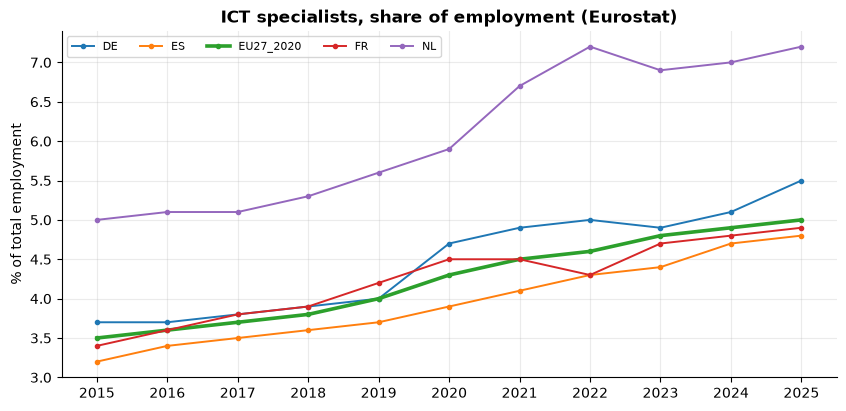

Eurostat quality flags in these points: {'e': 43, 'be': 14, 'b': 9, 'd': 8, 'bd': 2}


In [7]:
e = sel(m, dataset="eurostat_isoc_sks_itspt", metric="employment_share_pct", breakdown="")
e = e[e.country.isin(["EU27_2020", "DE", "FR", "ES", "NL"])]
p = e.pivot_table(index="year", columns="country", values="value").loc[2015:]
fig, ax = plt.subplots()
for c in p.columns: ax.plot(p.index, p[c], marker="o", ms=3, lw=2.6 if c == "EU27_2020" else 1.4, label=c)
ax.set_ylabel("% of total employment"); ax.set_title("ICT specialists, share of employment (Eurostat)")
ax.legend(fontsize=8, ncol=5); ax.set_xticks(p.index)
save(fig, "05_eurostat_ict_share"); plt.show()
print("Eurostat quality flags in these points:", e[e.quality_flag != ""].quality_flag.value_counts().to_dict())

## 6 · UK and games: the only place we can see game development
ONS BRES jobs (Great Britain, 'Employment' = employees + working owners), indexed to **2019 = 100**. BRES counts are *rounded*, so small codes look steppy.

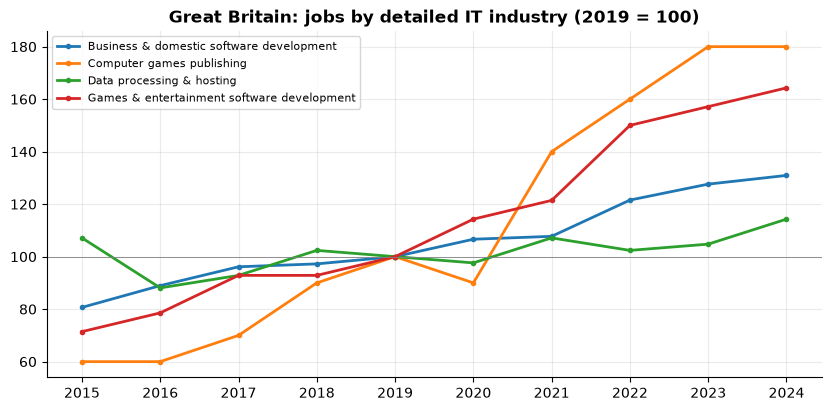

segment,Business & domestic software development,Computer games publishing,Data processing & hosting,Games & entertainment software development
year,,,,
2015,146.0,1.5,45.0,10.0
2016,161.0,1.5,37.0,11.0
2017,174.0,1.8,39.0,13.0
2018,176.0,2.2,43.0,13.0
2019,181.0,2.5,42.0,14.0
2020,193.0,2.2,41.0,16.0
2021,195.0,3.5,45.0,17.0
2022,220.0,4.0,43.0,21.0
2023,231.0,4.5,44.0,22.0


In [8]:
b = sel(m, dataset="ons_bres", breakdown="", industry_code=["58210", "62011", "62012", "63110"])
pb = b.pivot_table(index="year", columns="segment", values="value")
ib = pb / pb.loc[2019] * 100
fig, ax = plt.subplots()
for c in ib.columns: ax.plot(ib.index, ib[c], marker="o", ms=3, lw=2, label=c)
ax.axhline(100, color="grey", lw=0.6); ax.set_title("Great Britain: jobs by detailed IT industry (2019 = 100)")
ax.legend(fontsize=8); ax.set_xticks(ib.index)
save(fig, "06_uk_games_bres"); plt.show()
pb.round(1)

## 7 · What employers ask for (Hacker News "Who is hiring?")
Monthly share of posts mentioning each term (6-month rolling mean). **Startup-skewed**, and keyword matching ignores negation ("no remote"). Treat as an indicator of how one corner of the market changed.

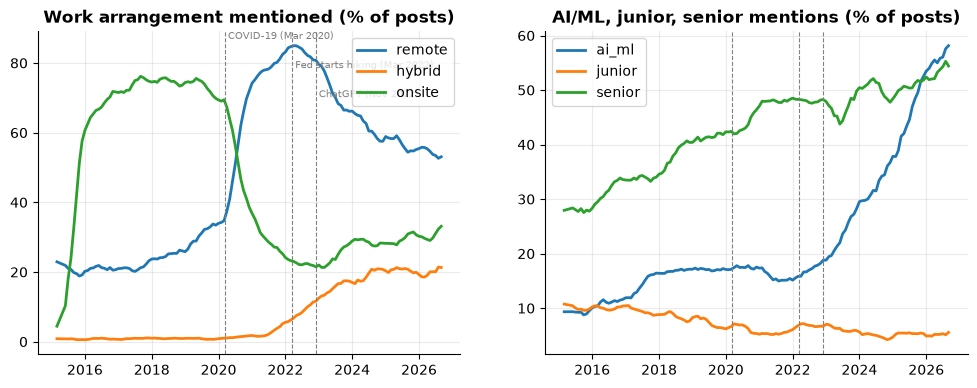

,2019,2025-26,change_pp
segment,,,
javascript,19.5,9.4,-10.2
react,32.6,23.9,-8.7
java,10.7,3.4,-7.3
ruby,11.4,4.6,-6.8
kotlin_android,10.4,4.0,-6.3
swift_ios,9.3,3.7,-5.6
azure,1.9,2.6,0.7
terraform,4.4,5.5,1.1
gcp,4.3,5.8,1.5


In [9]:
h = no_partial(sel(m, dataset="hn_whoishiring"))
if h.empty:
    print("No Hacker News rows yet: run `python collect.py --sources hn` then `python build_master.py`.")
else:
    sh = h[h.metric == "hn_post_share"].pivot_table(index="date", columns="segment", values="value")
    fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
    for c in ["remote", "hybrid", "onsite"]:
        if c in sh: axs[0].plot(sh.index, sh[c].rolling(6, min_periods=3).mean(), label=c, lw=2)
    axs[0].set_title("Work arrangement mentioned (% of posts)"); axs[0].legend(); events(axs[0])
    for c in ["ai_ml", "junior", "senior"]:
        if c in sh: axs[1].plot(sh.index, sh[c].rolling(6, min_periods=3).mean(), label=c, lw=2)
    axs[1].set_title("AI/ML, junior, senior mentions (% of posts)"); axs[1].legend(); events(axs[1], labels=False)
    save(fig, "07_hn_workarrangement_ai"); plt.show()
    skills = [c for c in sh.columns if c not in {"remote","hybrid","onsite","ai_ml","junior","senior","visa","games"}]
    top = sh.loc["2019":"2019"].mean().reindex(skills).dropna(), sh.loc["2025":"2026"].mean().reindex(skills).dropna()
    chg = pd.DataFrame({"2019": top[0], "2025-26": top[1]}).assign(change_pp=lambda d: d["2025-26"] - d["2019"]).sort_values("change_pp")
    display(pd.concat([chg.head(6), chg.tail(6)]).round(1))

## 8 · One timeline: do the indicators agree on *when*?
Each series scaled to its **own peak = 100** (from Feb 2020), so we compare timing, not size. Hiring demand (Indeed, Hacker News posts), the layoff wave, and US employment.

C:\Users\USER\AppData\Local\Temp\ipykernel_18476\3510057261.py:10: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  tl = pd.concat(parts, axis=1).loc["2020-02-01":]


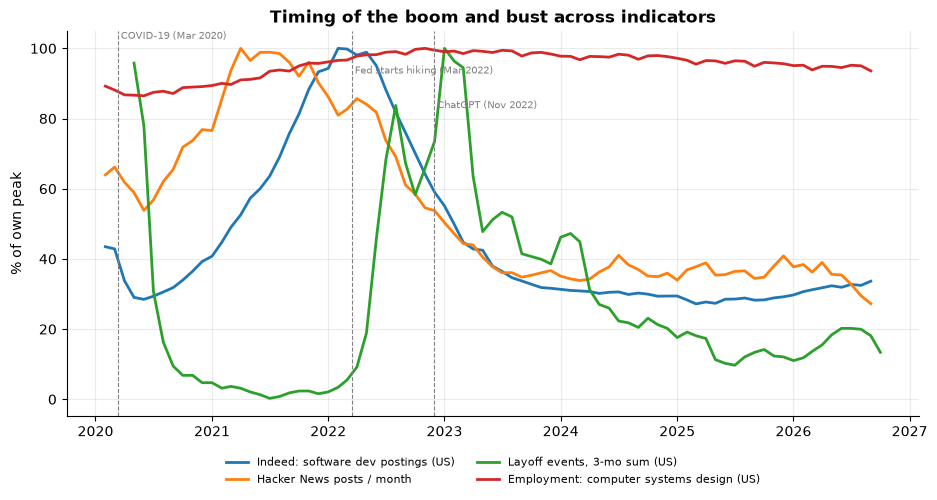

Month of peak by indicator:
Indeed: software dev postings (US)          2022-02
Hacker News posts / month                   2021-04
Layoff events, 3-mo sum (US)                2023-01
Employment: computer systems design (US)    2022-11


In [10]:
def monthly(df, col="value"): return df.set_index("date")[col]
parts = {}
us_sd = sd[sd.country == "US"]
if len(us_sd): parts["Indeed: software dev postings (US)"] = monthly(us_sd)
hp = h[h.metric == "hn_posts"] if not h.empty else h
if len(hp): parts["Hacker News posts / month"] = monthly(hp).rolling(3, min_periods=2).mean()
if "US" in ev: parts["Layoff events, 3-mo sum (US)"] = ev["US"].rolling(3).sum()
cs = ces[ces.segment.str.startswith("Computer systems design")]
if len(cs): parts["Employment: computer systems design (US)"] = monthly(cs)
tl = pd.concat(parts, axis=1).loc["2020-02-01":]
tl = tl / tl.max() * 100
fig, ax = plt.subplots(figsize=(11, 5))
for c in tl.columns: ax.plot(tl.index, tl[c], lw=2, label=c)
ax.set_ylabel("% of own peak"); ax.set_title("Timing of the boom and bust across indicators"); ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False); events(ax)
save(fig, "08_timeline_all"); plt.show()
print("Month of peak by indicator:"); print(tl.idxmax().dt.strftime("%Y-%m").to_string())

## What this notebook suggests, and what it cannot say
- **Visible:** a hiring-demand boom and bust (Indeed, Hacker News), a layoff wave peaking in 2023, a remote-work surge that has partly reversed, and a sharp rise in AI/ML mentions.
- **Not (yet) explained:** why employment plateaued rather than fell in the US and kept rising in Europe and the UK while postings collapsed.
- **Cannot say:** causes. Nothing here separates over-hiring, higher interest rates and AI; that needs the company- and metro-level data (next steps below).

**Next:** (1) metro panel for IT services (QCEW 5415 + Census ACS + house prices); (2) SEC financials to see whether over-hiring predicted layoffs; (3) Hacker News text models (topics, entry-level roles); (4) formal hypothesis tests. See the project explainer document for the plan.